### 11 ·Type hints and dataclasses 

### Warmup

In [2]:
# Calculate the area of a circle
def area_of_circle(r: float) -> float:
    return 3.14 * r * r


# Check whether a number is even
def is_even(n: int) -> bool:
    return n % 2 == 0


# Greet a person in English or Urdu
def greet(name: str, lang: str = "en") -> str:
    if lang == "en":
        return f"Hello, {name}"
    elif lang == "ur":
        return f"Salaam, {name}"
    else:
        return f"Unsupported language: {lang}"


# Test the functions
print(area_of_circle(3))
print(is_even(4))
print(greet("Ali"))
print(greet("Sara", "ur"))


28.259999999999998
True
Hello, Ali
Salaam, Sara


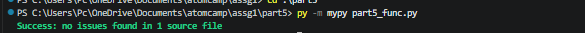

### Build: Product dataclass

In [3]:

from dataclasses import dataclass, field


@dataclass
class Product:
    name: str
    price: float
    stock: int
    tags: list[str] = field(default_factory=list)

    def __post_init__(self) -> None:
        if self.price < 0:
            raise ValueError("Price cannot be negative.")

        if self.stock < 0:
            raise ValueError("Stock cannot be negative.")


# Creating five products
products = [
    Product("Laptop", 150000, 5, ["Electronics", "Computer"]),
    Product("Mouse", 2500, 0, ["Electronics", "Accessory"]),
    Product("Keyboard", 5000, 0, ["Electronics"]),
    Product("Monitor", 40000, 3, ["Electronics"]),
    Product("Headphones", 8000, 0, ["Audio", "Accessory"])
]


# Display out-of-stock products
print("--- Out of Stock Products ---")

for product in products:
    if product.stock == 0:
        print(product.name)


--- Out of Stock Products ---
Mouse
Keyboard
Headphones


###

### Challenge: Save and load products

In [4]:
from dataclasses import dataclass, field, asdict
import json


@dataclass(order=True)
class Product:
    name: str
    price: float
    stock: int
    tags: list[str] = field(default_factory=list)

    def __post_init__(self) -> None:
        if self.price < 0 or self.stock < 0:
            raise ValueError("Price and stock cannot be negative.")


products = [
    Product("Laptop", 150000, 5, ["Electronics"]),
    Product("Mouse", 2500, 0, ["Accessory"]),
    Product("Keyboard", 5000, 0, ["Electronics"]),
    Product("Monitor", 40000, 3, ["Electronics"]),
    Product("Headphones", 8000, 0, ["Audio"])
]


# Save products to JSON
with open("products.json", "w") as file:
    json.dump([asdict(p) for p in products], file, indent=4)

print("Products saved successfully!")


# Load products from JSON
with open("products.json", "r") as file:
    data = json.load(file)

loaded_products = [Product(**d) for d in data]

print("\n--- Loaded Products ---")
for product in loaded_products:
    print(product)


# Sort products by price
loaded_products.sort(key=lambda p: p.price)

print("\n--- Products Sorted by Price ---")
for product in loaded_products:
    print(product.name, "Rs.", product.price)


Products saved successfully!

--- Loaded Products ---
Product(name='Laptop', price=150000, stock=5, tags=['Electronics'])
Product(name='Mouse', price=2500, stock=0, tags=['Accessory'])
Product(name='Keyboard', price=5000, stock=0, tags=['Electronics'])
Product(name='Monitor', price=40000, stock=3, tags=['Electronics'])
Product(name='Headphones', price=8000, stock=0, tags=['Audio'])

--- Products Sorted by Price ---
Mouse Rs. 2500
Keyboard Rs. 5000
Headphones Rs. 8000
Monitor Rs. 40000
Laptop Rs. 150000
